# PAD_lac / PAA Uncertainty & Match-Quality — MLB (v2)

Restart from `mlb_residual_patterns_uncertainty_v1.ipynb`. Drops the residual-pattern
screen and the §15 sign-convention rabbit hole — that work is still valid but isn't
where this notebook is headed. Keeps only what's needed to build and calibrate
PAA / PAD_lac against MAA / MAD (§1-4, unchanged), then two new pieces:

**Part A (§5):** Per-hitter and population-level uncertainty in the PAD_lac−MAD gap.
Three-way variance decomposition — envelope sampling noise (bootstrap), ground-truth
sampling noise (analytic, SD/√n_swings), and what's left over (structural). Answers
*is this hitter's gap distinguishable from zero, and how much of the average gap is
measurement vs. real disagreement.*

**Part B (§6):** Does swing/preference **match quality** predict performance
(wOBAcon, Barrel%)? Same-season version first (flagged as confound-prone — match
quality and outcome quality are both computed from the same batted-ball sample) and
a lagged version (prior-year match → next-year outcome) as the one to actually trust.
This is deliberately *not* a causal claim that closing the gap improves a hitter —
it only tests whether match quality is associated with, or a leading indicator of,
performance. Motivation: sidestep the player-eval-vs-player-dev question raised
against v1 — if match quality doesn't predict anything even at the association
level, there's no basis for a swing-change recommendation regardless of how well
PAD_lac itself is measured.

**Inputs:** `statcast_2024.parquet`, `statcast_2025.parquet` (same caches as v1/v4).

## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr, pearsonr, mannwhitneyu
from joblib import Parallel, delayed

from sklearn.linear_model import LinearRegression

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:.3f}".format)

PULL_CUTOFF_DEG = 15
AIR_LA_MIN      = 10

ANGLE_MIN, ANGLE_MAX = -30, 60
SPRAY_MIN, SPRAY_MAX = -45, 45
BIN_WIDTH        = 3
TOP_FRAC_PER_BIN = 0.20
TOP_N_METHOD2    = 15
MIN_BBE_LAC      = 30

MIN_BBE = 100
MIN_SWINGS_GT = 100   # min tracked swings for MAA/MAD ground truth

rng_global = np.random.default_rng(42)
print("Config OK")

Config OK


## 2. Metric Functions (unchanged from v1/v4)

In [2]:
def _envelope_peak_arrays(x, ev, x_min, x_max):
    """Marshall envelope: top-20%-per-bin parabola peak, averaged with the
    top-15-by-EV mean."""
    mask = (x >= x_min) & (x <= x_max) & ~np.isnan(x) & ~np.isnan(ev)
    x, ev = x[mask], ev[mask]
    if len(x) < 10:
        return np.nan

    k2 = min(TOP_N_METHOD2, max(3, int(np.ceil(0.2 * len(x)))))
    top2_idx = np.argpartition(ev, -k2)[-k2:] if len(ev) > k2 else np.arange(len(ev))
    method2 = x[top2_idx].mean()

    bins = np.arange(x_min, x_max + BIN_WIDTH, BIN_WIDTH)
    bin_idx = np.digitize(x, bins)
    env_x_parts, env_ev_parts = [], []
    for b_i in np.unique(bin_idx):
        m = bin_idx == b_i
        sub_x, sub_ev = x[m], ev[m]
        if len(sub_x) == 0:
            continue
        k = max(1, int(np.ceil(TOP_FRAC_PER_BIN * len(sub_x))))
        idx = np.argpartition(sub_ev, -k)[-k:] if len(sub_ev) > k else np.arange(len(sub_ev))
        env_x_parts.append(sub_x[idx])
        env_ev_parts.append(sub_ev[idx])

    if not env_x_parts:
        return method2
    env_x  = np.concatenate(env_x_parts)
    env_ev = np.concatenate(env_ev_parts)
    if len(env_x) < 5:
        return method2

    a, b, c = np.polyfit(env_x, env_ev, deg=2)
    if a < 0:
        v = -b / (2 * a)
        if x_min <= v <= x_max:
            method1 = v
        else:
            xs = np.linspace(x_min, x_max, 361)
            method1 = xs[np.argmax(np.polyval([a, b, c], xs))]
    else:
        method1 = env_x[np.argmax(env_ev)]

    return np.nanmean([method1, method2])


def _la_corrected_pad_arrays(la, sp, paa_val, min_n=MIN_BBE_LAC):
    mask = ~np.isnan(la) & ~np.isnan(sp)
    la_c, sp_c = la[mask], sp[mask]
    if len(la_c) < min_n or np.isnan(paa_val):
        return np.nan
    slope, intercept, *_ = stats.linregress(la_c, sp_c)
    return intercept + slope * paa_val


def compute_metrics_for_group(la, ev, sp):
    paa     = _envelope_peak_arrays(la, ev, ANGLE_MIN, ANGLE_MAX)
    pad_raw = _envelope_peak_arrays(sp, ev, SPRAY_MIN, SPRAY_MAX)
    pad_lac = _la_corrected_pad_arrays(la, sp, paa)
    return paa, pad_raw, pad_lac

print("Metric functions defined")

Metric functions defined


## 3. Load Statcast, Build BBE Frame + Batter-Season Metrics

In [3]:
def load_statcast(cache_path):
    p = Path(cache_path)
    if p.exists():
        print(f"Loading {p} …")
        return pd.read_parquet(p)
    raise FileNotFoundError(f"{p} not found — build the cache first.")

raw24 = load_statcast("statcast_2024.parquet"); raw24["season"] = 2024
raw25 = load_statcast("statcast_2025.parquet"); raw25["season"] = 2025
raw = pd.concat([raw24, raw25], ignore_index=True)

mlb = raw[
    (raw["type"] == "X") &
    raw["launch_speed"].notna() &
    raw["launch_angle"].notna() &
    raw["hc_x"].notna() & raw["hc_y"].notna() &
    raw["stand"].notna() &
    raw["batter"].notna() &
    raw["events"].notna()
].copy()

mlb["spray_deg"] = np.degrees(
    np.arctan((mlb["hc_x"] - 125.42) / (198.27 - mlb["hc_y"]))
) * 0.75
mlb["spray_pull"] = np.where(mlb["stand"] == "R", -mlb["spray_deg"], mlb["spray_deg"])
mlb["is_pull"]    = mlb["spray_pull"] > PULL_CUTOFF_DEG
mlb["is_air"]     = mlb["launch_angle"] >= AIR_LA_MIN
mlb["pull_air"]   = mlb["is_pull"] & mlb["is_air"]
mlb["hard_hit"]   = mlb["launch_speed"] >= 95

WOBA_W = {"single": 0.88, "double": 1.25, "triple": 1.58, "home_run": 2.03}
mlb["woba_val"] = mlb["events"].map(WOBA_W).fillna(0.0)

print(f"MLB BBE rows: {len(mlb):,}   batters: {mlb['batter'].nunique():,}")

Loading statcast_2024.parquet …
Loading statcast_2025.parquet …
MLB BBE rows: 252,710   batters: 1,241


In [4]:
grp = mlb.groupby(["batter", "season"])

batter_df = grp.agg(
    n_bbe        = ("launch_speed", "size"),
    pull_pct     = ("is_pull",   "mean"),
    air_ball_pct = ("is_air",    "mean"),
    pull_air_pct = ("pull_air",  "mean"),
    mean_ev      = ("launch_speed","mean"),
    ev_90        = ("launch_speed", lambda s: s.quantile(0.90)),
    hard_hit_pct = ("hard_hit",  "mean"),
    wOBAcon      = ("woba_val",  "mean"),
    stand        = ("stand", lambda s: s.mode().iloc[0]),
).reset_index()

metric_rows = []
for (b, s), g in grp:
    la, ev, sp = (g["launch_angle"].to_numpy(), g["launch_speed"].to_numpy(),
                  g["spray_pull"].to_numpy())
    paa, pad_raw, pad_lac = compute_metrics_for_group(la, ev, sp)
    metric_rows.append({"batter": b, "season": s, "PAA": paa,
                        "PAD_raw": pad_raw, "PAD_lac": pad_lac})
batter_df = batter_df.merge(pd.DataFrame(metric_rows), on=["batter", "season"])
batter_df["is_L"] = (batter_df["stand"] == "L").astype(int)

numeric_cols = batter_df.select_dtypes(include="number").columns
batter_df[numeric_cols] = batter_df[numeric_cols].astype("float64")

qual = batter_df[(batter_df["n_bbe"] >= MIN_BBE) &
                 batter_df["PAA"].notna() &
                 batter_df["PAD_lac"].notna()].copy()

print(f"Batter-seasons total: {len(batter_df)}   qualified (>= {MIN_BBE} BBE): {len(qual)}")

Batter-seasons total: 1862   qualified (>= 100 BBE): 800


## 4. Ground Truth: MAD & MAA, Calibration

Same empirical sign-convention derivation and full-sample calibrations
(`PAD_lac_cal`, `PAA_cal`) as v1. `ad_batter`/`aa_batter` are pooled across
seasons (grouped by `batter` only) — `combined`/`combined_aa` keep the
batter-season grain from `qual` and broadcast the pooled ground truth across
each batter's seasons.

In [5]:
# -- Attack direction (MAD) --------------------------------------------------
ad_bbe = raw[
    (raw["type"] == "X") &
    raw["attack_direction"].notna() &
    raw["hc_x"].notna() & raw["hc_y"].notna() &
    raw["stand"].notna()
].copy()
ad_bbe["spray_deg"] = np.degrees(
    np.arctan((ad_bbe["hc_x"] - 125.42) / (198.27 - ad_bbe["hc_y"]))
) * 0.75
ad_bbe = ad_bbe[ad_bbe["attack_direction"].between(-50, 50)]
ad_bbe = ad_bbe[ad_bbe["spray_deg"].between(-45, 45)]

signs = {}
for side in ["R", "L"]:
    sub = ad_bbe[ad_bbe["stand"] == side]
    r_sign = sub[["attack_direction", "spray_deg"]].corr().iloc[0, 1]
    signs[side] = np.sign(r_sign)
    print(f"  {side}HB: attack_direction vs spray_deg  r = {r_sign:+.3f}")

ad_bbe["ad_pull"] = np.where(
    ad_bbe["stand"] == "R",
    -ad_bbe["attack_direction"] * signs["R"],
     ad_bbe["attack_direction"] * signs["L"],
)

ad_batter = (
    ad_bbe.groupby("batter")
    .agg(ad_pull_mean=("ad_pull", "mean"),
         ad_sd=("ad_pull", "std"),
         n_swings_ad=("ad_pull", "count"))
    .reset_index()
)

# -- Attack angle (MAA) -------------------------------------------------------
aa_bbe = raw[
    (raw["type"] == "X") &
    raw["attack_angle"].notna() &
    raw["batter"].notna()
].copy()
aa_batter = (
    aa_bbe.groupby("batter")
    .agg(aa_measured_mean=("attack_angle", "mean"),
         aa_sd=("attack_angle", "std"),
         n_swings_aa=("attack_angle", "count"))
    .reset_index()
)

# -- Merge + calibrate (full-sample) -----------------------------------------
combined = qual.merge(
    ad_batter[ad_batter["n_swings_ad"] >= MIN_SWINGS_GT],
    on="batter", how="inner"
).dropna(subset=["PAD_lac", "ad_pull_mean"])

combined_aa = qual.merge(
    aa_batter[aa_batter["n_swings_aa"] >= MIN_SWINGS_GT],
    on="batter", how="inner"
).dropna(subset=["PAA", "aa_measured_mean"])

slope_cal, intercept_cal, r_lac, *_ = stats.linregress(
    combined["PAD_lac"], combined["ad_pull_mean"])
combined["PAD_lac_cal"] = intercept_cal + slope_cal * combined["PAD_lac"]

slope_cal_aa, intercept_cal_aa, r_paa, *_ = stats.linregress(
    combined_aa["PAA"], combined_aa["aa_measured_mean"])
combined_aa["PAA_cal"] = intercept_cal_aa + slope_cal_aa * combined_aa["PAA"]

print(f"\nPAD_lac vs MAD:  r = {r_lac:.3f}   (n={len(combined)})")
print(f"PAA vs MAA:      r = {r_paa:.3f}   (n={len(combined_aa)})")

# -- Residual tables ----------------------------------------------------------
resid_pad = combined.copy()
resid_pad["resid"]     = resid_pad["PAD_lac_cal"] - resid_pad["ad_pull_mean"]
resid_pad["abs_resid"] = resid_pad["resid"].abs()

resid_paa = combined_aa.copy()
resid_paa["resid"]     = resid_paa["PAA_cal"] - resid_paa["aa_measured_mean"]
resid_paa["abs_resid"] = resid_paa["resid"].abs()

print(f"\nresid_pad: n={len(resid_pad)}   |resid| median={resid_pad['abs_resid'].median():.2f} deg")
print(f"resid_paa: n={len(resid_paa)}   |resid| median={resid_paa['abs_resid'].median():.2f} deg")

  RHB: attack_direction vs spray_deg  r = +0.532
  LHB: attack_direction vs spray_deg  r = -0.489

PAD_lac vs MAD:  r = 0.622   (n=791)
PAA vs MAA:      r = 0.735   (n=796)

resid_pad: n=791   |resid| median=1.42 deg
resid_paa: n=796   |resid| median=1.47 deg


---
## 5. Part A — Uncertainty in (PAD_lac − MAD)

$$\mathrm{Var}(\text{resid}) = \underbrace{\mathrm{Var}(\widehat{\text{PAD\_lac}} - \text{PAD\_lac}_{true})}_{\text{envelope sampling noise (bootstrap)}} + \underbrace{\mathrm{Var}(\widehat{\text{MAD}} - \text{MAD}_{true})}_{\text{ground-truth sampling noise (analytic)}} + \underbrace{\sigma^2_{struct}}_{\text{real disagreement}}$$

Two deliverables: a per-hitter CI on the gap itself (`diff ± 1.96*se_diff`), and the
population-level split telling you how much of the average gap is measurement vs.
structural. Bootstrap keys are batter-season (PAD_lac_cal's grain); ground-truth SE
comes from `combined`'s pooled `ad_sd`/`n_swings_ad` broadcast across a batter's
seasons — same caveat as before: `se_gt` will be identical across a batter's own
seasons since MAD isn't re-split by year.

In [6]:
N_BOOT = 200

def bootstrap_padlac(la, ev, sp, n_boot=N_BOOT, seed=0):
    rng = np.random.default_rng(seed)
    n = len(la)
    lacs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        _, _, lac = compute_metrics_for_group(la[idx], ev[idx], sp[idx])
        lacs[i] = lac
    return np.nanstd(lacs)

def _boot_one(key, g):
    la = g["launch_angle"].to_numpy()
    ev = g["launch_speed"].to_numpy()
    sp = g["spray_pull"].to_numpy()
    return {"batter": key[0], "season": key[1],
            "se_lac_boot": bootstrap_padlac(la, ev, sp, seed=hash(key) % 2**31)}

keys = set(map(tuple, combined[["batter", "season"]].itertuples(index=False)))
groups = {k: g for k, g in mlb.groupby(["batter", "season"]) if k in keys}
print(f"Bootstrapping {len(groups)} batter-seasons x {N_BOOT} replicates ...")
boot_df = pd.DataFrame(Parallel(n_jobs=-1)(delayed(_boot_one)(k, g) for k, g in groups.items()))

D = combined.merge(boot_df, on=["batter", "season"])
D["diff"]     = D["PAD_lac_cal"] - D["ad_pull_mean"]
D["se_est"]   = np.abs(slope_cal) * D["se_lac_boot"]
D["se_gt"]    = D["ad_sd"] / np.sqrt(D["n_swings_ad"])
D["se_diff"]  = np.sqrt(D["se_est"]**2 + D["se_gt"]**2)
D["ci_lo"]    = D["diff"] - 1.96 * D["se_diff"]
D["ci_hi"]    = D["diff"] + 1.96 * D["se_diff"]
D["gap_significant"] = (D["ci_lo"] > 0) | (D["ci_hi"] < 0)

print(D[["batter", "season", "diff", "se_diff", "ci_lo", "ci_hi"]]
      .sort_values("se_diff").head(10).round(2))
print(f"\n{D['gap_significant'].mean():.1%} of hitters have a PAD_lac-MAD gap "
      f"distinguishable from zero at 95% confidence")

Bootstrapping 791 batter-seasons x 200 replicates ...
        batter   season   diff  se_diff  ci_lo  ci_hi
128 605141.000 2025.000 -3.160    0.600 -4.340 -1.980
328 663538.000 2025.000 -1.390    0.620 -2.620 -0.170
683 686469.000 2025.000 -1.020    0.640 -2.280  0.230
387 665489.000 2024.000 -2.740    0.640 -4.000 -1.470
598 677951.000 2025.000 -3.010    0.650 -4.280 -1.730
43  543760.000 2024.000 -1.190    0.650 -2.470  0.090
624 680776.000 2024.000 -0.520    0.660 -1.800  0.770
669 683002.000 2024.000  3.430    0.660  2.140  4.720
306 660271.000 2024.000  0.630    0.660 -0.670  1.940
290 656941.000 2025.000  2.670    0.660  1.370  3.970

36.8% of hitters have a PAD_lac-MAD gap distinguishable from zero at 95% confidence


PAD_lac vs MAD gap decomposition (deg^2):
  Var(resid)=5.25  est samp=0.72  GT samp=0.38  structural=4.14 (79%)  structural SD=2.03 deg


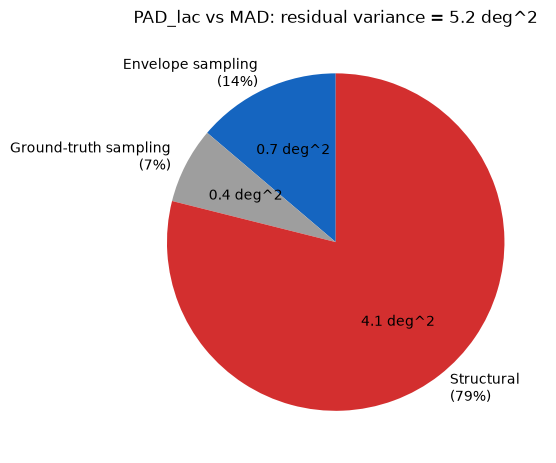

In [7]:
var_resid  = D["diff"].var()
var_est    = (D["se_est"]**2).mean()
var_gt     = (D["se_gt"]**2).mean()
var_struct = max(var_resid - var_est - var_gt, 0.0)

print(f"PAD_lac vs MAD gap decomposition (deg^2):")
print(f"  Var(resid)={var_resid:.2f}  est samp={var_est:.2f}  GT samp={var_gt:.2f}  "
      f"structural={var_struct:.2f} ({100*var_struct/var_resid:.0f}%)  "
      f"structural SD={np.sqrt(var_struct):.2f} deg")

fig, ax = plt.subplots(figsize=(5.5, 5))
parts = [var_est, var_gt, var_struct]
labels = [f"Envelope sampling\n({100*parts[0]/var_resid:.0f}%)",
          f"Ground-truth sampling\n({100*parts[1]/var_resid:.0f}%)",
          f"Structural\n({100*parts[2]/var_resid:.0f}%)"]
ax.pie(parts, labels=labels, colors=["#1565C0", "#9E9E9E", "#D32F2F"],
       autopct=lambda p: f"{p*var_resid/100:.1f} deg^2", startangle=90)
ax.set_title(f"PAD_lac vs MAD: residual variance = {var_resid:.1f} deg^2")
plt.tight_layout(); plt.show()

**Interpretation guide.** The structural share is the ceiling-setter:

- **Structural dominates** — more BBE won't close the gap. PAD_lac and MAD are
  related but genuinely different quantities; report PAD_lac as its own metric
  with the structural SD as the caveat rather than as "estimated attack direction."
- **Envelope sampling dominates** — the gap is mostly a small-sample problem, and
  per-hitter BBE-dependent intervals are the right way to communicate it.
- `se_diff`/`ci_lo`/`ci_hi` are the columns that go on a per-hitter card or the
  Streamlit board's error bars — that's the practical deliverable from this section.

---
## 6. Part B — Does Match Quality Predict Performance?

"Match" = negative absolute gap between preferred and measured, for both direction
and angle. Deliberately **not** testing whether closing the gap causes better
outcomes — only whether match quality is *associated with* (same-season) or a
*leading indicator of* (lagged) performance. The lagged version is the one to
trust: same-season match quality and same-season outcomes are both computed from
the same batted-ball sample, so a same-season correlation is confound-prone.

Outcomes: `wOBAcon`, `Barrel%`. Both partialled on `n_bbe` since noisier (low-BBE)
estimates mechanically produce larger apparent gaps regardless of anything real.

In [8]:
def partial_corr(x, y, control):
    """Partial Pearson r between x and y controlling for `control` (linear
    residualization of both)."""
    mask = ~(np.isnan(x) | np.isnan(y) | np.isnan(control))
    x, y, c = x[mask], y[mask], control[mask]
    if len(x) < 20:
        return np.nan, np.nan, len(x)
    rx = x - LinearRegression().fit(c.reshape(-1, 1), x).predict(c.reshape(-1, 1))
    ry = y - LinearRegression().fit(c.reshape(-1, 1), y).predict(c.reshape(-1, 1))
    r, p = pearsonr(rx, ry)
    return r, p, len(x)

# -- Batted-ball distribution / Barrel% ---------------------------------------
mlb["bb_type_calc"] = pd.cut(mlb["launch_angle"], bins=[-90, 10, 25, 50, 90],
                             labels=["gb", "ld", "fb", "pu"])
dist_spec = dict()
if "launch_speed_angle" in mlb.columns:
    dist_spec["barrel_pct"] = ("launch_speed_angle", lambda s: (s == 6).mean())
else:
    raise ValueError("launch_speed_angle not in mlb — check the raw Statcast column name for barrels")

bb_dist = mlb.groupby(["batter", "season"]).agg(**dist_spec).reset_index()
print(f"BB-distribution table (barrel_pct): {len(bb_dist)} batter-seasons")

BB-distribution table (barrel_pct): 1862 batter-seasons


In [11]:
D_aa = combined_aa.copy()
D_aa["diff_aa"] = D_aa["PAA_cal"] - D_aa["aa_measured_mean"]

MATCH = (D[["batter", "season", "diff", "n_bbe"]]
         .rename(columns={"diff": "diff_ad"})
         .merge(D_aa[["batter", "season", "diff_aa"]], on=["batter", "season"]))

MATCH["match_ad"] = -MATCH["diff_ad"].abs()
MATCH["match_aa"] = -MATCH["diff_aa"].abs()
MATCH["match_combined"] = -(
    (MATCH["diff_ad"].abs() - MATCH["diff_ad"].abs().mean()) / MATCH["diff_ad"].abs().std()
    + (MATCH["diff_aa"].abs() - MATCH["diff_aa"].abs().mean()) / MATCH["diff_aa"].abs().std()
) / 2

OUTCOME_COLS = ["wOBAcon", "barrel_pct"]
PERF = (qual[["batter", "season", "wOBAcon"]]                       # dropped n_bbe here
        .merge(bb_dist[["batter", "season", "barrel_pct"]], on=["batter", "season"], how="left"))

MATCH_SCORES = {"match_combined": "combined (AD+AA, z-scored)",
                "match_ad": "direction only", "match_aa": "angle only"}

print("=== Same-season (mechanical-confound risk — read with caution) ===")
same = MATCH.merge(PERF, on=["batter", "season"])
for score, label in MATCH_SCORES.items():
    print(f"\n-- match score: {label} --")
    for out in OUTCOME_COLS:
        d = same.dropna(subset=[score, out, "n_bbe"])
        r_raw, p_raw = pearsonr(d[score], d[out])
        r_part, p_part, n = partial_corr(d[score].to_numpy(dtype=float),
                                         d[out].to_numpy(dtype=float),
                                         d["n_bbe"].to_numpy(dtype=float))
        print(f"  {out:<14} raw r={r_raw:+.3f} (p={p_raw:.3f})   "
              f"n_bbe-partialled r={r_part:+.3f} (p={p_part:.3f})   n={n}")

=== Same-season (mechanical-confound risk — read with caution) ===

-- match score: combined (AD+AA, z-scored) --
  wOBAcon        raw r=+0.022 (p=0.530)   n_bbe-partialled r=-0.007 (p=0.838)   n=791
  barrel_pct     raw r=+0.027 (p=0.448)   n_bbe-partialled r=+0.009 (p=0.803)   n=791

-- match score: direction only --
  wOBAcon        raw r=-0.031 (p=0.391)   n_bbe-partialled r=-0.061 (p=0.084)   n=791
  barrel_pct     raw r=-0.028 (p=0.438)   n_bbe-partialled r=-0.046 (p=0.193)   n=791

-- match score: angle only --
  wOBAcon        raw r=+0.065 (p=0.069)   n_bbe-partialled r=+0.050 (p=0.159)   n=791
  barrel_pct     raw r=+0.069 (p=0.053)   n_bbe-partialled r=+0.060 (p=0.094)   n=791


In [12]:
# -- Lagged: year N match -> year N+1 outcome (the one to trust) ------------
match_prior = MATCH.copy()
match_prior["season"] = match_prior["season"] + 1
lagged = match_prior.merge(PERF, on=["batter", "season"], suffixes=("_prior", ""))

print(f"=== Lagged: prior-year match -> next-year outcome ===")
print(f"n hitter-years with both: {len(lagged)}")
for score, label in MATCH_SCORES.items():
    print(f"\n-- match score: {label} --")
    for out in OUTCOME_COLS:
        d = lagged.dropna(subset=[score, out, "n_bbe"])
        if len(d) < 20:
            print(f"  {out:<14} n too small ({len(d)}), skipping")
            continue
        r_raw, p_raw = pearsonr(d[score], d[out])
        r_part, p_part, n = partial_corr(d[score].to_numpy(dtype=float),
                                         d[out].to_numpy(dtype=float),
                                         d["n_bbe"].to_numpy(dtype=float))
        print(f"  {out:<14} raw r={r_raw:+.3f} (p={p_raw:.3f})   "
              f"n_bbe-partialled r={r_part:+.3f} (p={p_part:.3f})   n={n}")

=== Lagged: prior-year match -> next-year outcome ===
n hitter-years with both: 307

-- match score: combined (AD+AA, z-scored) --
  wOBAcon        raw r=-0.045 (p=0.430)   n_bbe-partialled r=-0.048 (p=0.405)   n=307
  barrel_pct     raw r=-0.026 (p=0.644)   n_bbe-partialled r=-0.027 (p=0.637)   n=307

-- match score: direction only --
  wOBAcon        raw r=-0.088 (p=0.126)   n_bbe-partialled r=-0.091 (p=0.113)   n=307
  barrel_pct     raw r=-0.087 (p=0.130)   n_bbe-partialled r=-0.088 (p=0.125)   n=307

-- match score: angle only --
  wOBAcon        raw r=+0.020 (p=0.722)   n_bbe-partialled r=+0.020 (p=0.732)   n=307
  barrel_pct     raw r=+0.046 (p=0.422)   n_bbe-partialled r=+0.046 (p=0.423)   n=307


**How to read this.** If the lagged correlations are near zero while the
same-season ones look strong, that's the same-batted-ball-sample confound talking
— drop the same-season finding, it doesn't support anything. If the lagged version
holds up (even attenuated from same-season), that's evidence match quality is a
leading indicator of performance independent of the confound — and it's a claim
you can bring to a skeptical coach as "hitters who match tend to perform better,"
not a prescriptive "change your swing" directive.

`n` for the lagged version is capped at one row per hitter who qualified in both
2024 and 2025 — a null result here is weaker evidence of "no relationship" than a
null with more years of data would be. Worth revisiting once more FL/MLB seasons
are available rather than treating one year of lag as final.

**Still open, not addressed by this notebook:** whether this generalizes to FL at
FL's lower BBE counts, and whether `match_ad` vs `match_aa` individually (rather
than the combined score) is doing the work — rerun the loop above scoped to just
one score if the combined result is interesting enough to chase further.